In [ ]:
import pandas as pd

train=pd.read_csv("../data/raw/train.csv")
train.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [15]:
#check data quality
print(train.isnull().sum())
print( train.duplicated().sum())
print( train.nunique())
print(train.shape)

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64
0
id             3000888
date              1684
store_nbr           54
family              33
sales           379610
onpromotion        362
dtype: int64
(3000888, 6)


In [28]:
print (f"mean is {train["sales"].mean()}")
print(f" median is {train["sales"].median()}")
print (f"max is {train["sales"].max()}")
print(f" min is {train["sales"].min()}")
zero_cols=(train["sales"]==0).sum()
print(f" sales cotaining zeros are {zero_cols} cells")

mean is 357.77574911261877
 median is 11.0
max is 124717.0
 min is 0.0
 sales cotaining zeros are 939130 cells


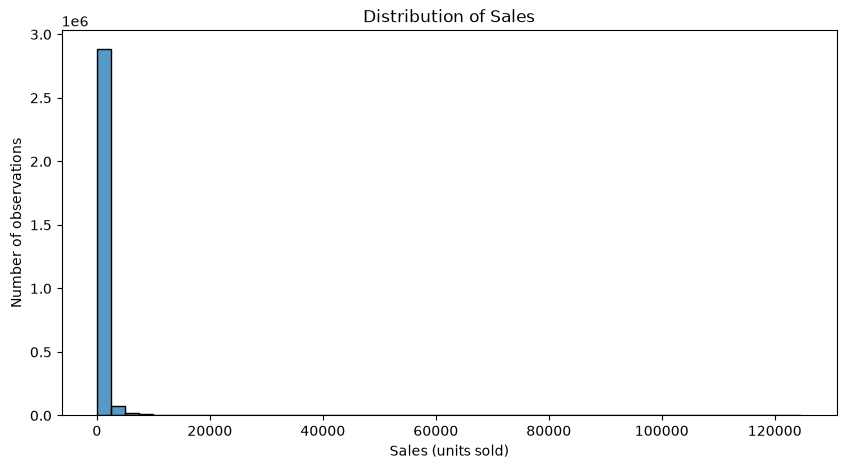

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 5))
sns.histplot(data=train,x="sales",bins=50)
plt.title("Distribution of Sales")
plt.xlabel("Sales (units sold)")
plt.ylabel("Number of observations")

plt.show()


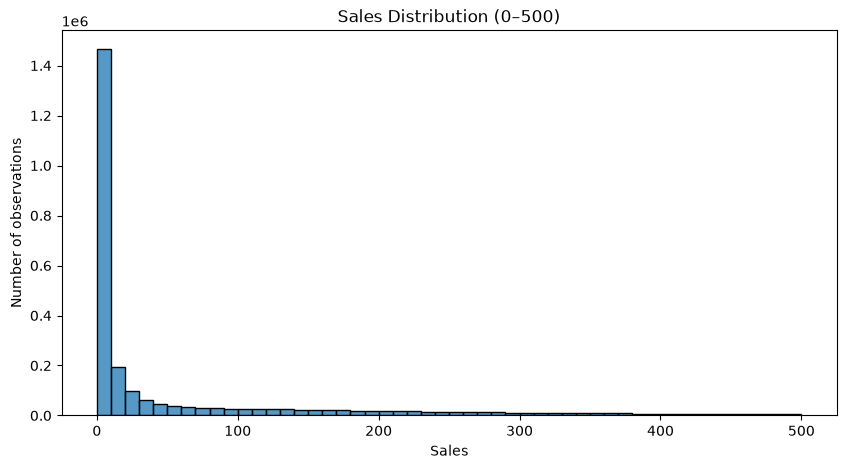

In [38]:
#visualize sales that  are lesss than 500
plt.figure(figsize=(10, 5))
sns.histplot(data=train[train["sales"]<=500],x="sales",bins=50)
plt.title("Sales Distribution (0–500)")
plt.xlabel("Sales")
plt.ylabel("Number of observations")

plt.show()

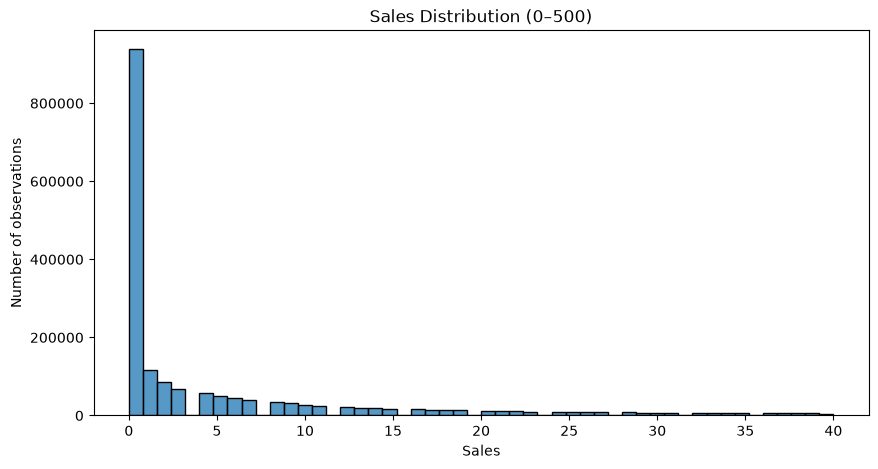

In [40]:
plt.figure(figsize=(10, 5))
sns.histplot(data=train[train["sales"]<=40],x="sales",bins=50)
plt.title("Sales Distribution (0–500)")
plt.xlabel("Sales")
plt.ylabel("Number of observations")

plt.show()

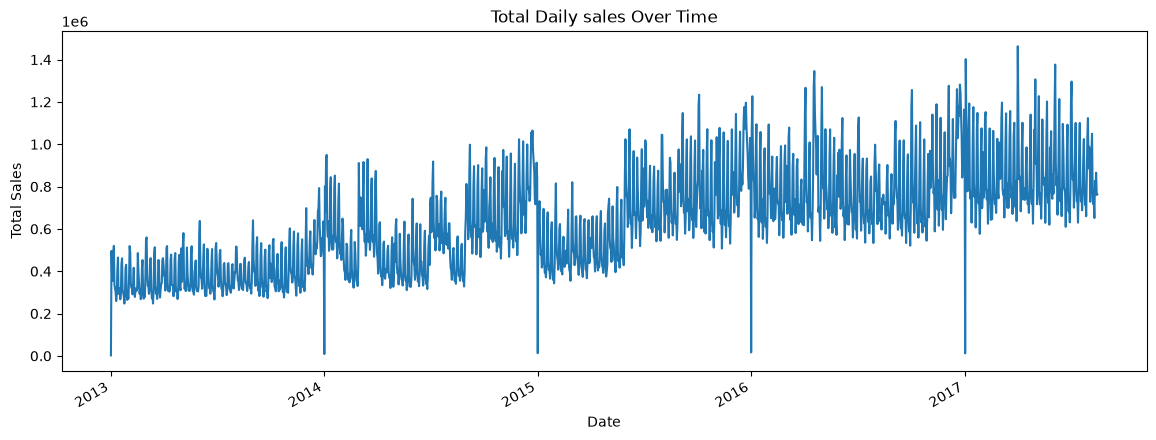

In [48]:
train["date"]=pd.to_datetime(train["date"])
daily_sales=train.groupby('date')["sales"].sum()

plt.figure(figsize=(14,5))
daily_sales.plot()
plt.title("Total Daily sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.show()


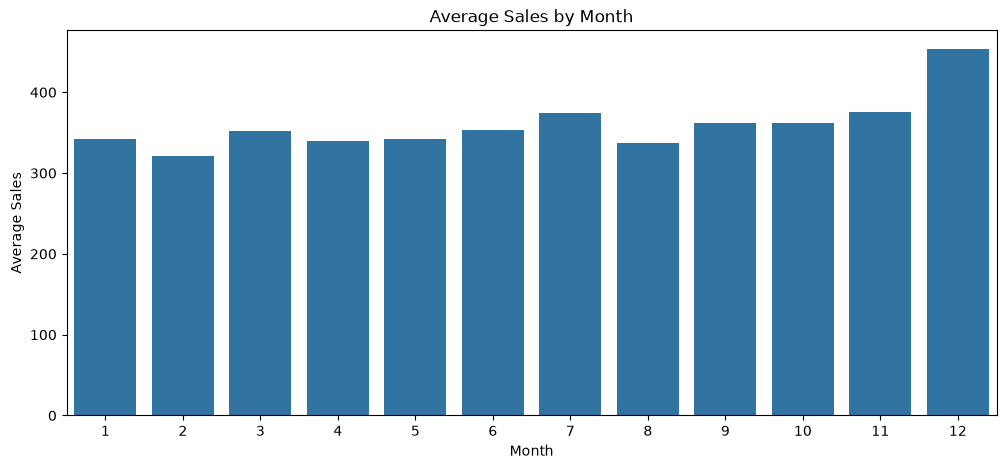

Index([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12], dtype='int32', name='date')

In [ ]:
monthly_sales=train.groupby(train["date"].dt.month)["sales"].mean()
plt.figure(figsize=(12, 5))

sns.barplot(x=monthly_sales.index, y=monthly_sales.values)

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Sales")

plt.show()



In [66]:
# Let's sort by family sales 
family_sales = train.groupby("family")["sales"].sum()

family_sales = family_sales.sort_values(ascending=False)

family_sales.head(10)


family
GROCERY I        3.434627e+08
BEVERAGES        2.169545e+08
PRODUCE          1.227047e+08
CLEANING         9.752129e+07
DAIRY            6.448771e+07
BREAD/BAKERY     4.213395e+07
POULTRY          3.187600e+07
MEATS            3.108647e+07
PERSONAL CARE    2.459205e+07
DELI             2.411032e+07
Name: sales, dtype: float64

In [92]:
#Let's group by month then by family 
family_deccember_sales=train[train["date"].dt.month==12]
family_december_sales =family_deccember_sales.groupby('family')['sales'].sum().sort_values(ascending=False)
family_december_sales.head(10)

family
GROCERY I        3.172662e+07
BEVERAGES        1.864239e+07
PRODUCE          1.168322e+07
CLEANING         8.032230e+06
DAIRY            5.403695e+06
FROZEN FOODS     4.109247e+06
BREAD/BAKERY     2.982672e+06
POULTRY          2.737742e+06
MEATS            2.255324e+06
PERSONAL CARE    2.041434e+06
Name: sales, dtype: float64

In [109]:
train["month"] = train["date"].dt.month
monthly_family_sales = train.pivot_table(
    index="family",
    columns="month",
    values="sales",
    aggfunc="sum"
)
peak_month = monthly_family_sales.idxmax(axis=1)
peak_month.value_counts()
peak_month[peak_month==7]

family
BABY CARE              7
BEAUTY                 7
BEVERAGES              7
CELEBRATION            7
HOME AND KITCHEN II    7
HOME CARE              7
LADIESWEAR             7
MEATS                  7
PET SUPPLIES           7
PRODUCE                7
dtype: int32

In [119]:
monthly_family_avg = train.pivot_table(
    index="family",
    columns="month",
    values="sales",
    aggfunc="mean"
)

In [121]:
peak_avg_month = monthly_family_avg.idxmax(axis=1)
peak_avg_month.value_counts()
peak_avg_month[peak_avg_month == 12]

family
AUTOMOTIVE                 12
BEAUTY                     12
BEVERAGES                  12
CELEBRATION                12
CLEANING                   12
DAIRY                      12
DELI                       12
EGGS                       12
FROZEN FOODS               12
GROCERY I                  12
GROCERY II                 12
HARDWARE                   12
HOME AND KITCHEN I         12
LIQUOR,WINE,BEER           12
MAGAZINES                  12
PERSONAL CARE              12
PET SUPPLIES               12
PLAYERS AND ELECTRONICS    12
POULTRY                    12
PREPARED FOODS             12
PRODUCE                    12
dtype: int32